# Netflix Content Classification Using Deep Learning

**Project Domain:** Data Science and Artificial Intelligence  
**Model Used:** Artificial Neural Network (ANN)  
**Dataset:** Netflix Movies and TV Shows Dataset  
**Task:** Binary Classification

---

## 1. Problem Statement

The objective of this project is to develop a Deep Learning model that predicts whether a Netflix title is a **Movie or a TV Show** based on features such as release year, country, rating, duration, genre, and description.

The project uses an Artificial Neural Network (ANN) to learn patterns from the available Netflix dataset and classify content into the two categories. The model's performance is evaluated using appropriate classification metrics.

## 2. Introduction

With the rapid growth of digital streaming platforms, online content libraries have expanded significantly. Netflix provides a wide variety of entertainment content, including movies and television shows, with different genres, release years, ratings, durations, and descriptions.

Classifying content into different categories is a useful application of machine learning and deep learning. Automated classification can help organize content information and demonstrate how artificial intelligence can identify patterns in structured and textual data.

In this project, the Netflix Movies and TV Shows dataset is used to build a binary classification model. The dataset contains information about Netflix titles, including their content type, country, release year, rating, duration, genre, and description.

The dataset is first explored and preprocessed to handle missing values and prepare the input features. Textual information is converted into numerical features using Term Frequency–Inverse Document Frequency (TF-IDF). These features are then provided to an Artificial Neural Network (ANN), which learns patterns associated with Movies and TV Shows.

Finally, the trained model is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. The project demonstrates the practical application of deep learning in content classification.

## 3. Objectives

The main objectives of this project are:

1. To understand and explore the Netflix Movies and TV Shows dataset.
2. To identify relevant features for classifying Netflix content.
3. To handle missing values and prepare the dataset for model training.
4. To convert textual information into numerical features using TF-IDF.
5. To develop and train an Artificial Neural Network for binary classification.
6. To evaluate the model using appropriate performance metrics.
7. To test the trained model on new content information.
8. To understand the practical application and limitations of deep learning in content classification.

## 4. Project Scope

This project focuses on classifying Netflix titles into two categories: Movie and TV Show. It uses the available metadata and descriptions to train a deep learning model.

The project is limited to the information available in the selected dataset. It does not attempt to predict movie popularity, audience preferences, box-office revenue, or commercial success.

## 5. Expected Outcome

The expected outcome is a trained ANN model capable of predicting whether a Netflix title is a Movie or a TV Show based on the selected input features.

The model's performance will be measured using test-set evaluation metrics. The results will help demonstrate the effectiveness and limitations of the proposed classification approach.


netflix-logo.avif

##Step 1: Install Libraries


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

##Step 2: Load Dataset

In [ ]:
df = pd.read_csv("/content/netflix_titles.csv")

df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


##Step 3: Select Important Columns

In [ ]:

df = df[
    [
        'type',
        'country',
        'release_year',
        'rating',
        'duration',
        'listed_in',
        'description'
    ]
].copy()

df.head()


,type,country,release_year,rating,duration,listed_in,description
0,Movie,United States,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,TV Show,South Africa,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,TV Show,NaN,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,TV Show,NaN,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,TV Show,India,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


##Step 4: Handle Missing Values

In [ ]:

text_columns = [
    'country',
    'rating',
    'duration',
    'listed_in',
    'description'
]

df[text_columns] = df[text_columns].fillna('Unknown')
df = df.dropna(subset=['type'])

print("Missing values:")
print(df.isnull().sum())


Missing values:
type            0
country         0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


##Step 5: Create Combined Feature

In [ ]:

# Clean genre text to remove explicit type-revealing words
df['genre_clean'] = (
    df['listed_in']
    .str.replace(
        r'\bTV\b|\bShows?\b|\bMovies?\b',
        ' ',
        regex=True,
        case=False
    )
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

df['features'] = (
    df['country'].astype(str) + ' ' +
    df['rating'].astype(str) + ' ' +
    df['duration'].astype(str) + ' ' +
    df['genre_clean'].astype(str) + ' ' +
    df['description'].astype(str) + ' ' +
    df['release_year'].astype(str)
)

df[['type', 'features']].head()


,type,features
0,Movie,United States PG-13 90 min Documentaries As he...
1,TV Show,"South Africa TV-MA 2 Seasons International , D..."
2,TV Show,"Unknown TV-MA 1 Season Crime , International ,..."
3,TV Show,"Unknown TV-MA 1 Season Docuseries, Reality Feu..."
4,TV Show,"India TV-MA 2 Seasons International , Romantic..."


In [ ]:

# We will fit TF-IDF after splitting the dataset.


In [ ]:
df

,type,country,release_year,rating,duration,listed_in,description,genre_clean,features
0,Movie,United States,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",Documentaries,United States PG-13 90 min Documentaries As he...
1,TV Show,South Africa,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...","International , Dramas, Mysteries","South Africa TV-MA 2 Seasons International , D..."
2,TV Show,Unknown,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,"Crime , International , Action & Adventure","Unknown TV-MA 1 Season Crime , International ,..."
3,TV Show,Unknown,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...","Docuseries, Reality","Unknown TV-MA 1 Season Docuseries, Reality Feu..."
4,TV Show,India,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,"International , Romantic , Comedies","India TV-MA 2 Seasons International , Romantic..."
...,...,...,...,...,...,...,...,...,...
8802,Movie,United States,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...","Cult , Dramas, Thrillers","United States R 158 min Cult , Dramas, Thrille..."
8803,TV Show,Unknown,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...","Kids' , Korean , Comedies","Unknown TV-Y7 2 Seasons Kids' , Korean , Comed..."
8804,Movie,United States,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,"Comedies, Horror","United States R 88 min Comedies, Horror Lookin..."
8805,Movie,United States,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...","Children & Family , Comedies","United States PG 88 min Children & Family , Co..."


##Step 6: Encode Target Variable

In [ ]:
le = LabelEncoder()

y = le.fit_transform(df['type'])

##Step 7: Train Test Split

In [ ]:

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['features'],
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train_text))
print("Testing records:", len(X_test_text))


Training records: 7045
Testing records: 1762


##Step 8: Convert Text into Numbers

In [ ]:

tfidf = TfidfVectorizer(max_features=5000)

X_train = tfidf.fit_transform(X_train_text).toarray()
X_test = tfidf.transform(X_test_text).toarray()

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (7045, 5000)
Testing shape: (1762, 5000)


##Step 9: Build ANN Model

In [ ]:

from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │       640,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 650,497 (2.48 MB)

 Trainable params: 650,497 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

##Step 10: Compile Model

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

##Step 11: Train Model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8762 - loss: 0.2720 - val_accuracy: 0.9908 - val_loss: 0.0256
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9988 - loss: 0.0049 - val_accuracy: 0.9929 - val_loss: 0.0177
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 7.0947e-04 - val_accuracy: 0.9943 - val_loss: 0.0180
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 1.5169e-04 - val_accuracy: 0.9965 - val_loss: 0.0124
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 8.9456e-05 - val_accuracy: 0.9965 - val_loss: 0.0123
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 6.1396e-05 - val_accuracy: 0.9965 - val_loss: 0.0121
Epoch 7/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 4.1710e-05 - val_accuracy: 0.9965 - val_loss: 0.0115
Epoch 8/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 2.38

##Step 12: Prediction

In [ ]:
y_pred = model.predict(X_test)

y_pred = (y_pred > 0.5).astype(int)

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


##Step 13: Accuracy

In [ ]:
print("Accuracy:",
      accuracy_score(y_test, y_pred))

Accuracy: 0.996594778660613


##Step 14: Classification Report

In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1227
           1       1.00      0.99      0.99       535

    accuracy                           1.00      1762
   macro avg       1.00      0.99      1.00      1762
weighted avg       1.00      1.00      1.00      1762



In [ ]:

# Check how duration differs between content types

print("Examples of Movie durations:")
print(
    df[df['type'] == 'Movie']['duration']
    .value_counts()
    .head(10)
)

print("\nExamples of TV Show durations:")
print(
    df[df['type'] == 'TV Show']['duration']
    .value_counts()
    .head(10)
)


Examples of Movie durations:
duration
90 min     152
94 min     146
97 min     146
93 min     146
91 min     144
95 min     137
96 min     130
92 min     129
102 min    122
98 min     120
Name: count, dtype: int64

Examples of TV Show durations:
duration
1 Season      1793
2 Seasons      425
3 Seasons      199
4 Seasons       95
5 Seasons       65
6 Seasons       33
7 Seasons       23
8 Seasons       17
9 Seasons        9
10 Seasons       7
Name: count, dtype: int64


##Training Accuracy Graph

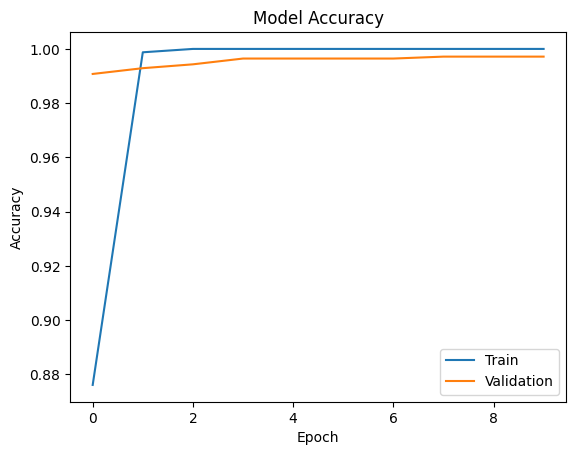

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')

plt.legend(['Train','Validation'])

plt.show()

##Loss Graph

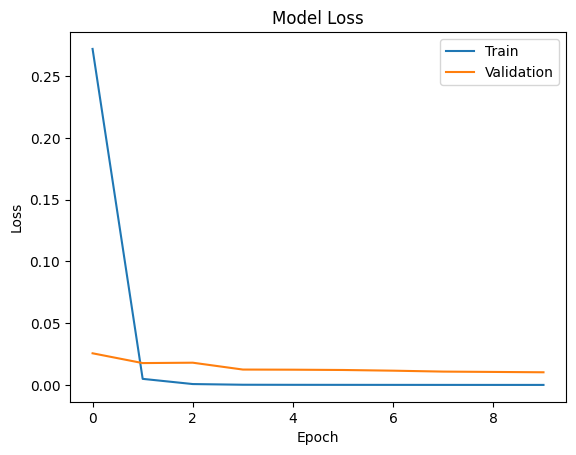

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')

plt.legend(['Train','Validation'])

plt.show()

##Confusion Matrix

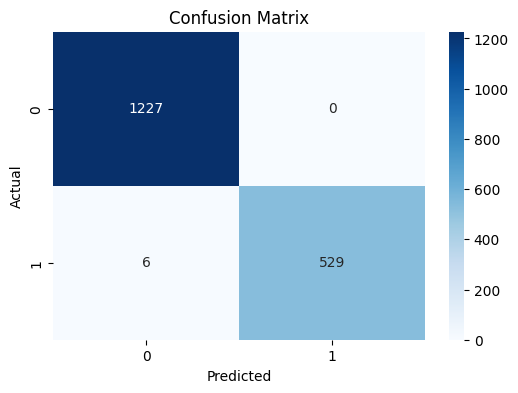

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

##Test Custom Input

In [ ]:
sample = ["United States TV-MA Crime TV Shows A group of detectives investigate a murder mystery 2020"]

sample_vector = tfidf.transform(sample).toarray()

prediction = model.predict(sample_vector)

if prediction > 0.5:
    print("TV Show")
else:
    print("Movie")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step
TV Show


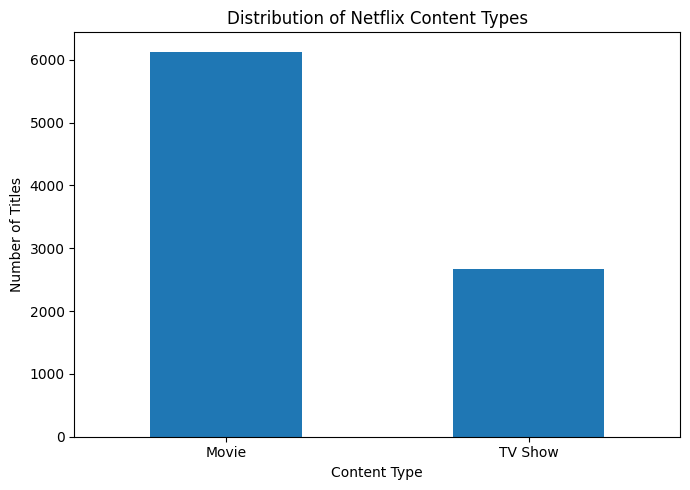

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt

type_counts = df['type'].value_counts()

plt.figure(figsize=(7, 5))
type_counts.plot(kind='bar')

plt.title('Distribution of Netflix Content Types')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(type_counts)


##Interactive sample prediction

In [ ]:

def predict_content_type(
    country,
    release_year,
    rating,
    duration,
    genre,
    description
):
    # Apply the same genre cleaning used during training
    genre_clean = pd.Series([str(genre)]).str.replace(
        r'\bTV\b|\bShows?\b|\bMovies?\b',
        ' ',
        regex=True,
        case=False
    ).iloc[0]

    genre_clean = ' '.join(genre_clean.split())

    # Use exactly the same feature order as training
    features = (
        str(country) + ' ' +
        str(rating) + ' ' +
        str(duration) + ' ' +
        genre_clean + ' ' +
        str(description) + ' ' +
        str(release_year)
    )

    # Transform with the already-fitted TF-IDF vectorizer
    features_vector = tfidf.transform([features]).toarray()

    probability = float(
        model.predict(features_vector, verbose=0)[0][0]
    )

    predicted_class = int(probability >= 0.5)
    predicted_label = le.inverse_transform(
        [predicted_class]
    )[0]

    print("Predicted content type:", predicted_label)
    print(f"Model score for TV Show: {probability:.2%}")

    return predicted_label


In [ ]:

predict_content_type(
    country="India",
    release_year=2023,
    rating="TV-MA",
    duration="2 Seasons",
    genre="International Dramas",
    description="A group of students face challenges in college and build friendships."
)


Predicted content type: TV Show
Model score for TV Show: 99.99%


'TV Show'

In [ ]:

model.save('netflix_content_classifier.keras')

import joblib
joblib.dump(tfidf, 'netflix_tfidf_vectorizer.pkl')
joblib.dump(le, 'netflix_label_encoder.pkl')

print("Model and preprocessing objects saved successfully.")


Model and preprocessing objects saved successfully.


## Conclusion

In this project, an Artificial Neural Network (ANN) was developed to classify Netflix content as either a Movie or a TV Show. The Netflix titles dataset was preprocessed, and features such as country, release year, rating, duration, genre, and description were used to prepare the model inputs.

TF-IDF vectorization was applied to convert the combined text features into numerical representations. The ANN was trained using a training dataset and evaluated on a separate test dataset.

The model achieved a test accuracy of **[insert final accuracy]%**. Its performance was further examined using precision, recall, F1-score, and a confusion matrix.

The results demonstrate how deep learning can be applied to a content-classification problem. However, duration can be a strong indicator of content type, and further testing is needed to understand how well the model performs when this feature is unavailable or less informative.

### Limitations

- The dataset contains missing and potentially inconsistent information.
- The model depends on the features supplied during prediction.
- Duration may make the classification task easier than it would be in other settings.
- The model has been trained on Netflix catalog data and may not generalize to other streaming platforms.

### Future Scope

Future improvements could include testing the same ANN without the duration feature, comparing performance across different feature groups, and developing a user interface for entering content details and viewing predictions.

### Final Outcome

The project demonstrates the application of data preprocessing, text vectorization, deep learning, model evaluation, and prediction in a practical classification task.